In [1]:
import numpy as np # digunakan untuk melakukan perhitungan aritmatik
import pandas as pd # untuk memanggil data eksternal

# Library untuk visualisasi data
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# untuk melakukan preprocessing data
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler, LabelEncoder, OneHotEncoder

In [2]:
df=pd.read_csv("/content/cirrhosis.csv")
print(df)

      ID  N_Days Status             Drug    Age Sex Ascites Hepatomegaly  \
0      1     400      D  D-penicillamine  21464   F       Y            Y   
1      2    4500      C  D-penicillamine  20617   F       N            Y   
2      3    1012      D  D-penicillamine  25594   M       N            N   
3      4    1925      D  D-penicillamine  19994   F       N            Y   
4      5    1504     CL          Placebo  13918   F       N            Y   
..   ...     ...    ...              ...    ...  ..     ...          ...   
413  414     681      D              NaN  24472   F     NaN          NaN   
414  415    1103      C              NaN  14245   F     NaN          NaN   
415  416    1055      C              NaN  20819   F     NaN          NaN   
416  417     691      C              NaN  21185   F     NaN          NaN   
417  418     976      C              NaN  19358   F     NaN          NaN   

    Spiders Edema  Bilirubin  Cholesterol  Albumin  Copper  Alk_Phos    SGOT  \
0      

Featur Selection

In [3]:
df.drop(columns=['ID','N_Days'], inplace=True)
df


,Status,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage
0,D,D-penicillamine,21464,F,Y,Y,Y,Y,14.5,261.0,2.60,156.0,1718.0,137.95,172.0,190.0,12.2,4.0
1,C,D-penicillamine,20617,F,N,Y,Y,N,1.1,302.0,4.14,54.0,7394.8,113.52,88.0,221.0,10.6,3.0
2,D,D-penicillamine,25594,M,N,N,N,S,1.4,176.0,3.48,210.0,516.0,96.10,55.0,151.0,12.0,4.0
3,D,D-penicillamine,19994,F,N,Y,Y,S,1.8,244.0,2.54,64.0,6121.8,60.63,92.0,183.0,10.3,4.0
4,CL,Placebo,13918,F,N,Y,Y,N,3.4,279.0,3.53,143.0,671.0,113.15,72.0,136.0,10.9,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
413,D,NaN,24472,F,NaN,NaN,NaN,N,1.2,NaN,2.96,NaN,NaN,NaN,NaN,174.0,10.9,3.0
414,C,NaN,14245,F,NaN,NaN,NaN,N,0.9,NaN,3.83,NaN,NaN,NaN,NaN,180.0,11.2,4.0
415,C,NaN,20819,F,NaN,NaN,NaN,N,1.6,NaN,3.42,NaN,NaN,NaN,NaN,143.0,9.9,3.0
416,C,NaN,21185,F,NaN,NaN,NaN,N,0.8,NaN,3.75,NaN,NaN,NaN,NaN,269.0,10.4,3.0


Checking Duplicated Dataset

In [4]:
df.duplicated().sum()

np.int64(0)

Check Missing Value

In [5]:
df.isnull().sum()

,0
Status,0
Drug,106
Age,0
Sex,0
Ascites,106
Hepatomegaly,106
Spiders,106
Edema,0
Bilirubin,0
Cholesterol,134


Melihat Informasi Dataset

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Status         418 non-null    object 
 1   Drug           312 non-null    object 
 2   Age            418 non-null    int64  
 3   Sex            418 non-null    object 
 4   Ascites        312 non-null    object 
 5   Hepatomegaly   312 non-null    object 
 6   Spiders        312 non-null    object 
 7   Edema          418 non-null    object 
 8   Bilirubin      418 non-null    float64
 9   Cholesterol    284 non-null    float64
 10  Albumin        418 non-null    float64
 11  Copper         310 non-null    float64
 12  Alk_Phos       312 non-null    float64
 13  SGOT           312 non-null    float64
 14  Tryglicerides  282 non-null    float64
 15  Platelets      407 non-null    float64
 16  Prothrombin    416 non-null    float64
 17  Stage          412 non-null    float64
dtypes: float64

Handling Missing Value

In [7]:
# Mengecek Persentase Data Yang Hilang di Atribut Drug
outlet_size = df['Drug'].isna().mean() * 100
print('Persentase Data Hilang Di Atribut Drug : {:.2f}%'.format(outlet_size))

Persentase Data Hilang Di Atribut Drug : 25.36%


<Axes: >

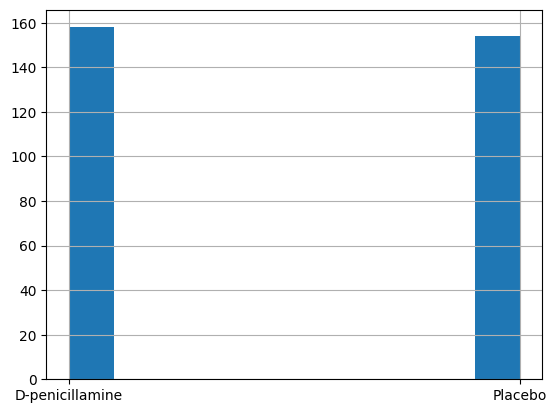

In [8]:
df1 = df.copy()
# Mengecek Histogram Data
df1['Drug'].hist()

In [9]:
df1

,Status,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage
0,D,D-penicillamine,21464,F,Y,Y,Y,Y,14.5,261.0,2.60,156.0,1718.0,137.95,172.0,190.0,12.2,4.0
1,C,D-penicillamine,20617,F,N,Y,Y,N,1.1,302.0,4.14,54.0,7394.8,113.52,88.0,221.0,10.6,3.0
2,D,D-penicillamine,25594,M,N,N,N,S,1.4,176.0,3.48,210.0,516.0,96.10,55.0,151.0,12.0,4.0
3,D,D-penicillamine,19994,F,N,Y,Y,S,1.8,244.0,2.54,64.0,6121.8,60.63,92.0,183.0,10.3,4.0
4,CL,Placebo,13918,F,N,Y,Y,N,3.4,279.0,3.53,143.0,671.0,113.15,72.0,136.0,10.9,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
413,D,NaN,24472,F,NaN,NaN,NaN,N,1.2,NaN,2.96,NaN,NaN,NaN,NaN,174.0,10.9,3.0
414,C,NaN,14245,F,NaN,NaN,NaN,N,0.9,NaN,3.83,NaN,NaN,NaN,NaN,180.0,11.2,4.0
415,C,NaN,20819,F,NaN,NaN,NaN,N,1.6,NaN,3.42,NaN,NaN,NaN,NaN,143.0,9.9,3.0
416,C,NaN,21185,F,NaN,NaN,NaN,N,0.8,NaN,3.75,NaN,NaN,NaN,NaN,269.0,10.4,3.0


In [10]:
# Mengganti Nilai Yang Hilang
df1['Drug']=df1['Drug'].fillna('D-penicillamine')
# Mengecek Nilai Yang Hilang
df1['Drug'].isna().sum()

np.int64(0)

,count
Drug,
D-penicillamine,264
Placebo,154


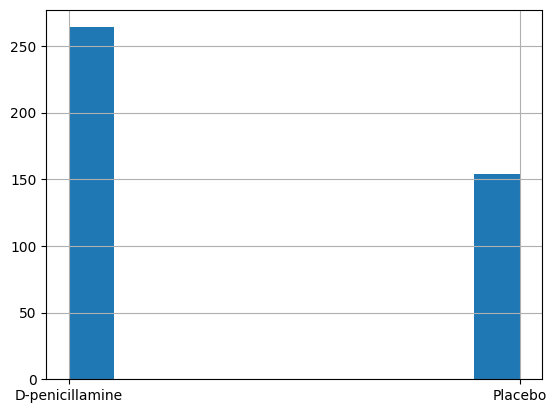

In [11]:
# Mengcek Dengan Histogram
df1['Drug'].hist()
# Mengecek Jumlah Nilai Tiap Katagori
df1['Drug'].value_counts()

In [12]:
# Dapat Dilihat NIlainya Hampir Sama Jadi Tidak EFektif
# Jika Mengisi Nilai Missing Value Dengan Modus, Maka akan digunakan
# Mengisi missing value dengan menggunakan nilai sebelum atau sesudah
df2 = df.copy()

In [13]:
# Mengganti Nilai Yang Hilang
df2['Drug']=df2['Drug'].fillna(method='pad')
df['Drug']=df2['Drug']
# Mengecek Nilai Yang Hilang
df2['Drug'].isna().sum()

/tmp/ipykernel_805/3307359891.py:2: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df2['Drug']=df2['Drug'].fillna(method='pad')


np.int64(0)

,count
Drug,
Placebo,260
D-penicillamine,158


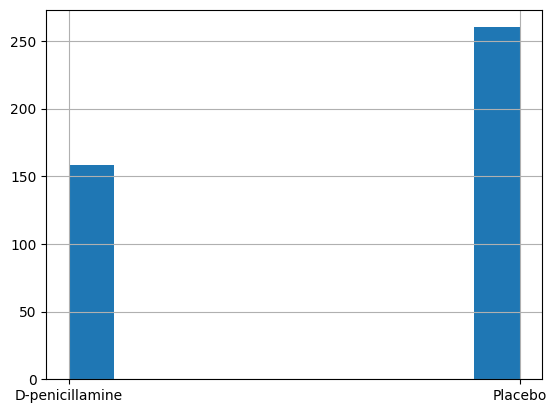

In [14]:
# Mengcek Dengan Histogram
df2['Drug'].hist()
# Mengecek Jumlah Nilai Tiap Katagori
df2['Drug'].value_counts()

In [15]:
# Mengecek Persentase Data Yang Hilang di Atribut Ascites
outlet_size = df['Ascites'].isna().mean() * 100
print('Persentase Data Hilang Di Atribut Ascites : {:.2f}%'.format(outlet_size))

Persentase Data Hilang Di Atribut Ascites : 25.36%


<Axes: >

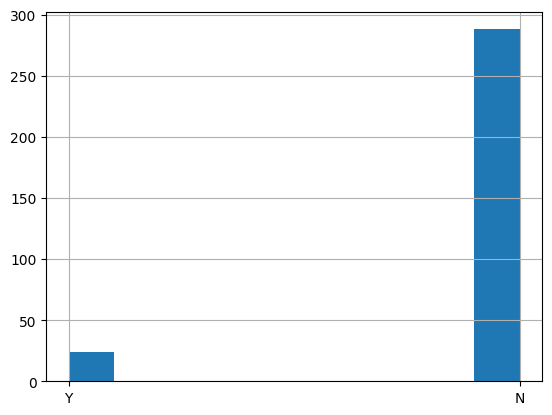

In [16]:
df1 = df.copy()
# Mengecek Histogram Data
df1['Ascites'].hist()

In [17]:
# Mengganti Nilai Yang Hilang
df1['Ascites']=df1['Ascites'].fillna('N')
df['Ascites']=df1['Ascites']
# Mengecek Nilai Yang Hilang
df1['Ascites'].isna().sum()

np.int64(0)

,count
Ascites,
N,394
Y,24


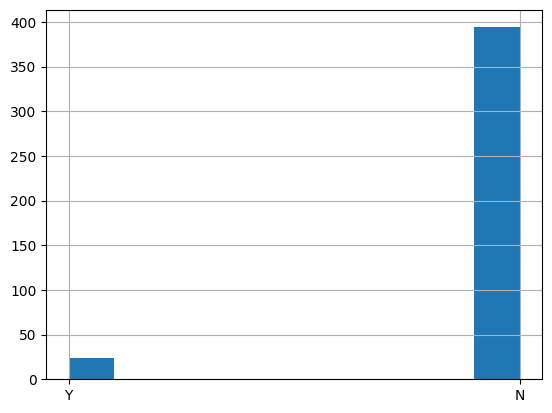

In [18]:
# Mengcek Dengan Histogram
df1['Ascites'].hist()
# Mengecek Jumlah Nilai Tiap Katagori
df1['Ascites'].value_counts()

In [19]:
# Mengecek Persentase Data Yang Hilang di Atribut Hepatomegaly
outlet_size = df['Hepatomegaly'].isna().mean() * 100
print('Persentase Data Hilang Di Atribut Hepatomegaly : {:.2f}%'.format(outlet_size))

Persentase Data Hilang Di Atribut Hepatomegaly : 25.36%


<Axes: >

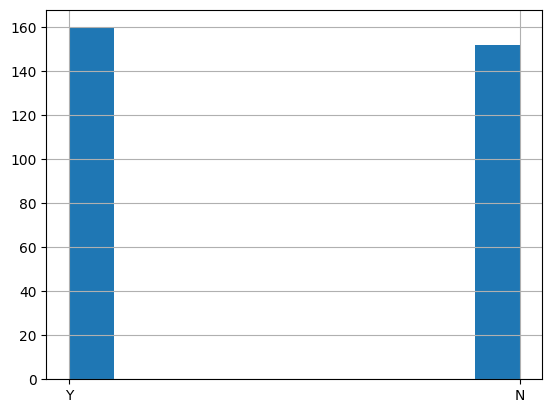

In [20]:
df1 = df.copy()
# Mengecek Histogram Data
df1['Hepatomegaly'].hist()

In [21]:
# Mengganti Nilai Yang Hilang
df1['Hepatomegaly']=df1['Hepatomegaly'].fillna('Y')
df['Hepatomegaly']=df1['Hepatomegaly']
# Mengecek Nilai Yang Hilang
df1['Hepatomegaly'].isna().sum()

np.int64(0)

,count
Hepatomegaly,
Y,266
N,152


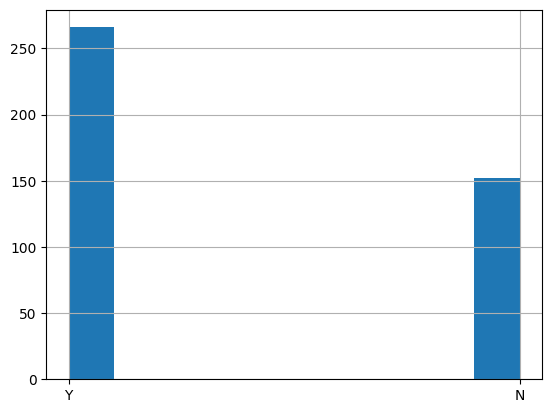

In [22]:
# Mengcek Dengan Histogram
df1['Hepatomegaly'].hist()
# Mengecek Jumlah Nilai Tiap Katagori
df1['Hepatomegaly'].value_counts()

In [23]:
# Mengecek Persentase Data Yang Hilang di Atribut Spiders
outlet_size = df['Spiders'].isna().mean() * 100
print('Persentase Data Hilang Di Atribut Spiders : {:.2f}%'.format(outlet_size))

Persentase Data Hilang Di Atribut Spiders : 25.36%


<Axes: >

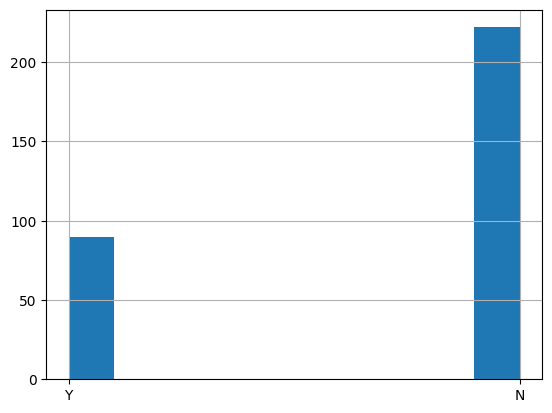

In [24]:
df1 = df.copy()
# Mengecek Histogram Data
df1['Spiders'].hist()

In [25]:
# Mengganti Nilai Yang Hilang
df1['Spiders']=df1['Spiders'].fillna('N')
df['Spiders']=df1['Spiders']
# Mengecek Nilai Yang Hilang
df1['Spiders'].isna().sum()

np.int64(0)

,count
Spiders,
N,328
Y,90


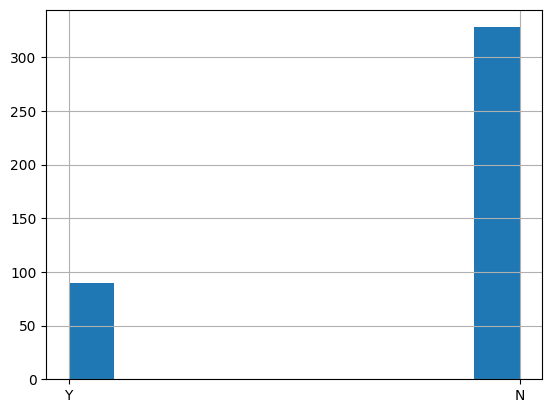

In [26]:
# Mengcek Dengan Histogram
df1['Spiders'].hist()
# Mengecek Jumlah Nilai Tiap Katagori
df1['Spiders'].value_counts()

Melihat Distribusi dari Variabel Input yang memiliki Nilai Numerik

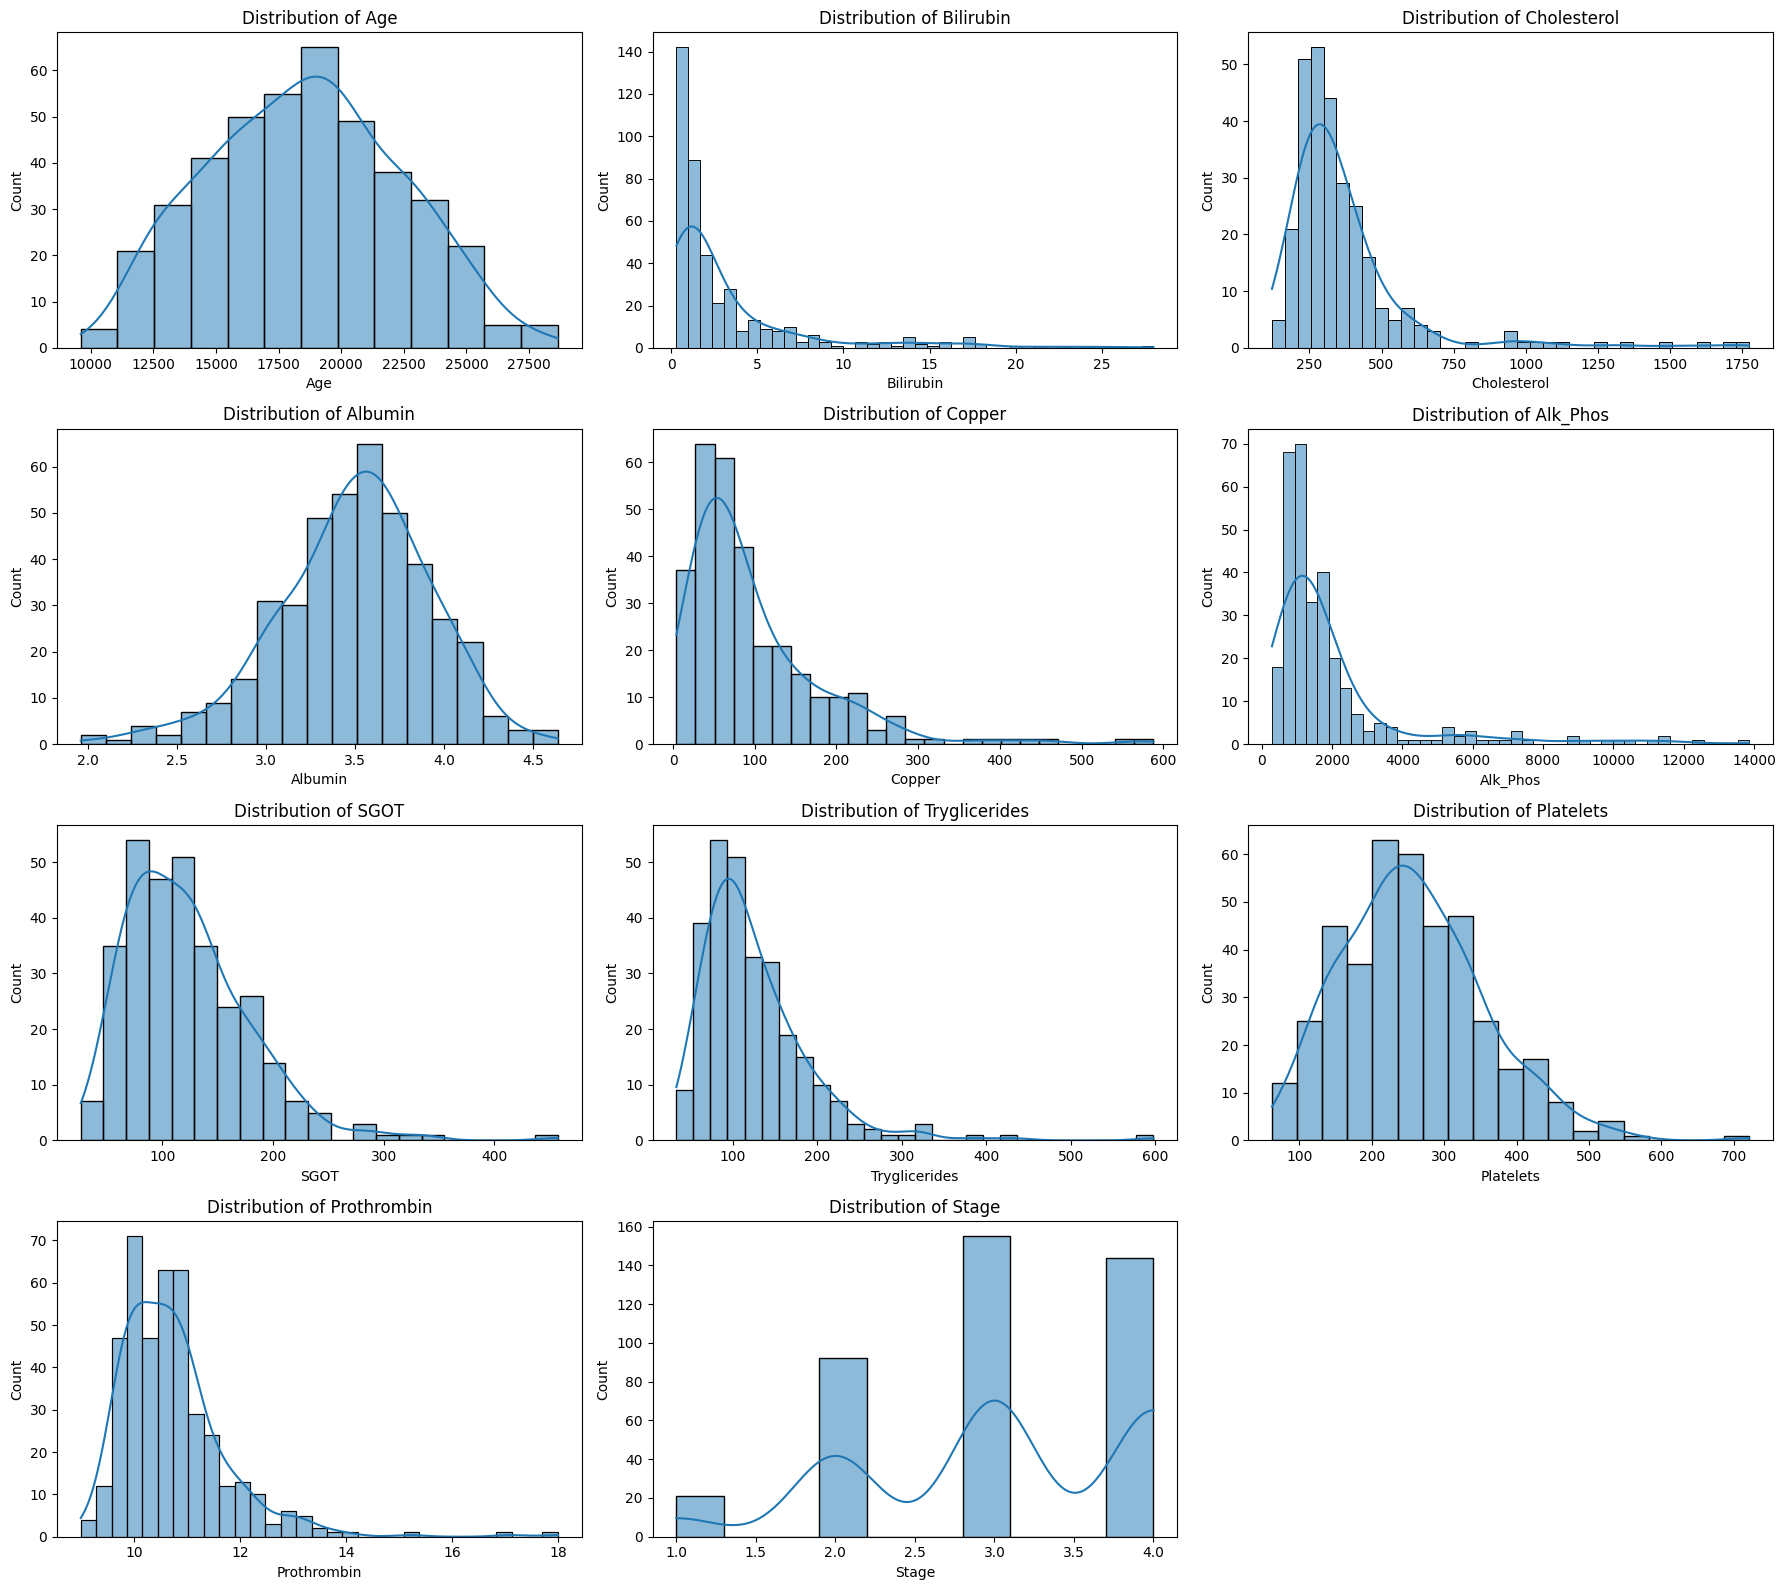

In [27]:
numeric_columns = [ 'Age', 'Bilirubin', 'Cholesterol', 'Albumin', 'Copper', 'Alk_Phos', 'SGOT', 'Tryglicerides', 'Platelets', 'Prothrombin', 'Stage']
# Mengatur tata letak subplot
num_rows = 4  # Jumlah baris subplot
num_cols = 3  # Jumlah kolom subplot
fig, axes = plt.subplots(num_rows, num_cols, figsize=(18, 16))  # Ukuran gambar subplot

# Menyusun histogram-histogram dalam subplot
for i, column in enumerate(numeric_columns):
    row = i // num_cols  # Menghitung baris ke berapa
    col = i % num_cols   # Menghitung kolom ke berapa
    sns.histplot(df[column], kde=True, ax=axes[row, col])  # Gambar histogram pada subplot yang sesuai
    axes[row, col].set_title(f"Distribution of {column}")  # Atur judul subplot

# Menghilangkan subplot yang tidak digunakan
for i in range(len(numeric_columns), num_rows * num_cols):
    fig.delaxes(axes.flatten()[i])

plt.tight_layout()  # Menyusun subplot dengan rapi
plt.show()  # Tampilkan gambar subplot

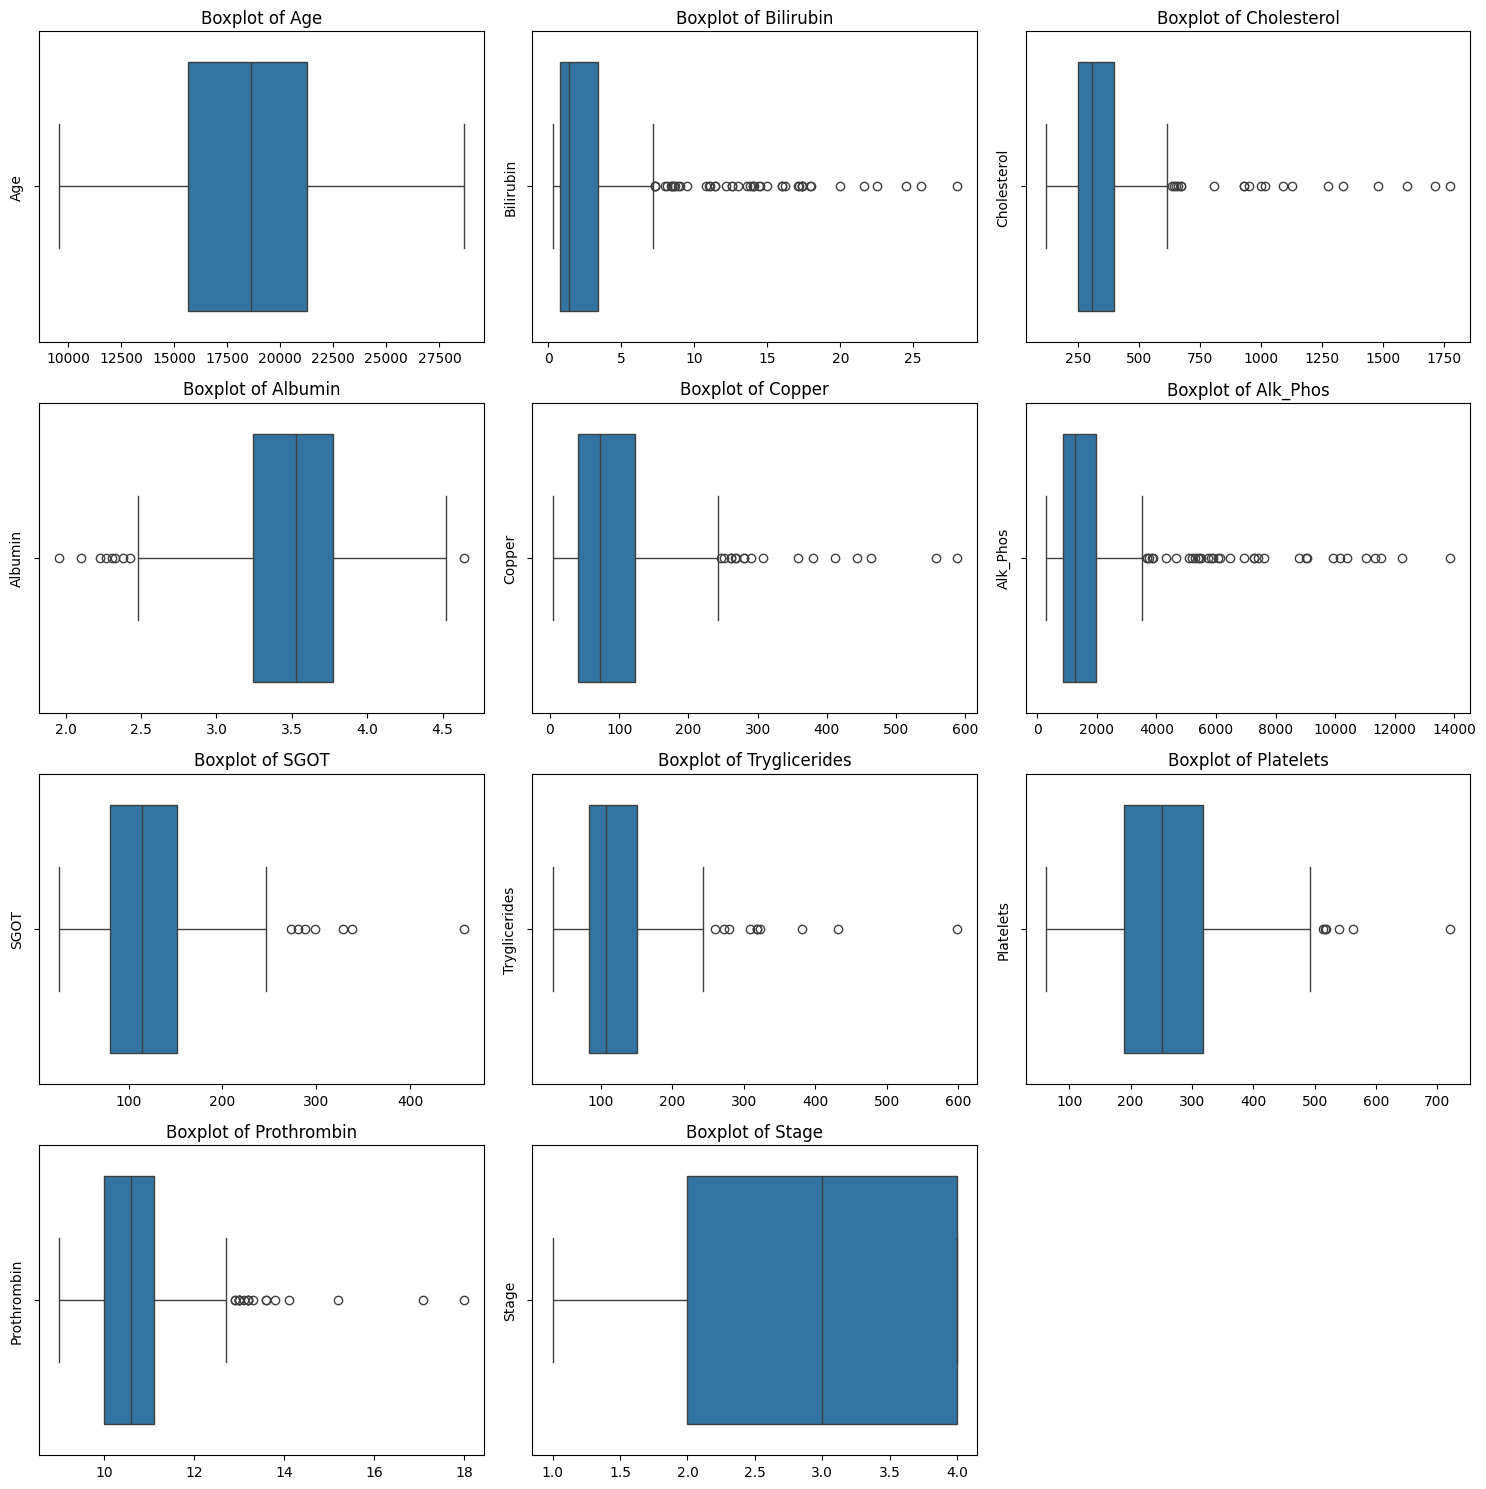

In [28]:
# Mengatur tampilan boxplot dengan matplotlib dan seaborn
num_cols = 3  # Jumlah kolom dalam tata letak boxplot
num_rows = (len(numeric_columns) + num_cols - 1) // num_cols  # Jumlah baris dalam tata letak boxplot

plt.figure(figsize=(15, 15))  # Ukuran gambar boxplot

# Loop untuk menggambar boxplot untuk setiap kolom numerik
for i, column in enumerate(numeric_columns, 1):
    plt.subplot(num_rows, num_cols, i)  # Menentukan posisi subplot dalam tata letak
    sns.boxplot(x=df[column])  # Menggambar boxplot untuk kolom numerik tertentu
    plt.title(f"Boxplot of {column}")  # Judul boxplot
    plt.xlabel("")  # Menghilangkan label sumbu x pada setiap subplot
    plt.ylabel(column)  # Menambahkan label sumbu y sebagai nama kolom

plt.tight_layout()  # Menyusun subplot dengan rapi
plt.show()  # Menampilkan gambar boxplot

In [29]:
# Kolom-kolom yang akan diisi dengan nilai mean
columns_to_fill = ['Bilirubin', 'Cholesterol', 'Copper', 'Alk_Phos', 'SGOT', 'Tryglicerides', 'Platelets', 'Prothrombin', 'Stage']

# Mengisi nilai NaN dengan mean untuk kolom-kolom tertentu
df[columns_to_fill] = df[columns_to_fill].fillna(df[columns_to_fill].mean())

# Tampilkan dataframe setelah mengisi nilai NaN dengan mean
print(df)

    Status             Drug    Age Sex Ascites Hepatomegaly Spiders Edema  \
0        D  D-penicillamine  21464   F       Y            Y       Y     Y   
1        C  D-penicillamine  20617   F       N            Y       Y     N   
2        D  D-penicillamine  25594   M       N            N       N     S   
3        D  D-penicillamine  19994   F       N            Y       Y     S   
4       CL          Placebo  13918   F       N            Y       Y     N   
..     ...              ...    ...  ..     ...          ...     ...   ...   
413      D          Placebo  24472   F       N            Y       N     N   
414      C          Placebo  14245   F       N            Y       N     N   
415      C          Placebo  20819   F       N            Y       N     N   
416      C          Placebo  21185   F       N            Y       N     N   
417      C          Placebo  19358   F       N            Y       N     N   

     Bilirubin  Cholesterol  Albumin      Copper     Alk_Phos        SGOT  

Melakukan Transformasi Untuk data Numerik

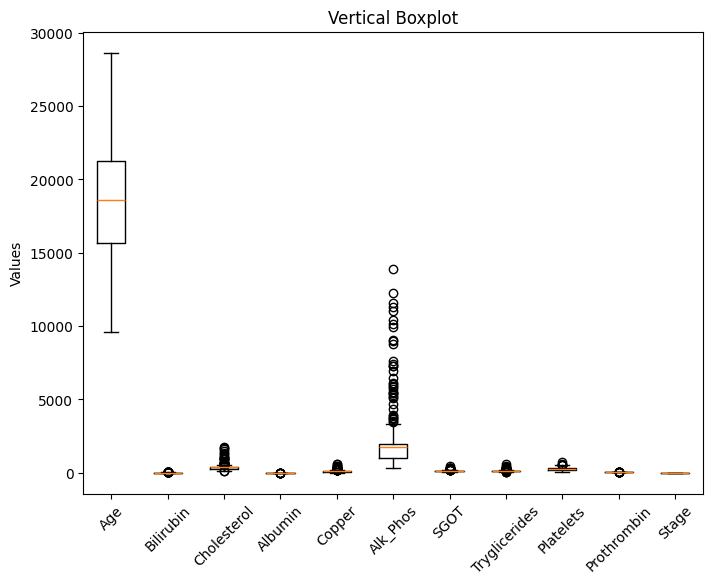

In [30]:
# Mengambil seluruh kolom numerik
df_columns_to_fill_ = df.select_dtypes(include=['number'])

# Membuat boxplot vertikal
plt.figure(figsize=(8, 6))
plt.boxplot(df_columns_to_fill_.dropna().values, vert=True)

plt.title('Vertical Boxplot')
plt.ylabel('Values')
plt.xticks(
    range(1, len(df_columns_to_fill_.columns) + 1),
    df_columns_to_fill_.columns,
    rotation=45
)

plt.show()

In [31]:
# Karena Data numerik pada dataset semuanya tidak memiliki distribusi yang mendekati normal sertahampir semua memiliki outliers sehingga normalisasi
# yang paling tepat adalah Min,Max Scaller
# Inisialisasi StandardScaler
scaler = StandardScaler()

# Normalisasi Min-Max pada kolom yang dipilih
df_columns_to_normalize= scaler.fit_transform(df_columns_to_fill_)
df_columns_to_fill_=df_columns_to_normalize

# Tampilkan DataFrame setelah normalisasi
print(df_columns_to_normalize)


[[ 7.68941125e-01  2.56215232e+00 -5.68568478e-01 ... -6.91659942e-01
   1.44184557e+00  1.11559551e+00]
 [ 5.46705953e-01 -4.81758761e-01 -3.53738632e-01 ... -3.71755492e-01
  -1.29360081e-01 -2.77511320e-02]
 [ 1.85256717e+00 -4.13611498e-01 -1.01394743e+00 ... -1.09412038e+00
   1.24544486e+00  1.11559551e+00]
 ...
 [ 5.99706549e-01 -3.68179990e-01 -2.97845437e-16 ... -1.17667637e+00
  -8.16762552e-01 -2.77511320e-02]
 [ 6.95737332e-01 -5.49906024e-01 -2.97845437e-16 ...  1.23580430e-01
  -3.25760787e-01 -2.77511320e-02]
 [ 2.16370557e-01 -5.72621779e-01 -2.97845437e-16 ...  9.59459799e-01
  -1.29360081e-01  1.11559551e+00]]


In [32]:
df

,Status,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage
0,D,D-penicillamine,21464,F,Y,Y,Y,Y,14.5,261.000000,2.60,156.000000,1718.000000,137.950000,172.000000,190.0,12.2,4.0
1,C,D-penicillamine,20617,F,N,Y,Y,N,1.1,302.000000,4.14,54.000000,7394.800000,113.520000,88.000000,221.0,10.6,3.0
2,D,D-penicillamine,25594,M,N,N,N,S,1.4,176.000000,3.48,210.000000,516.000000,96.100000,55.000000,151.0,12.0,4.0
3,D,D-penicillamine,19994,F,N,Y,Y,S,1.8,244.000000,2.54,64.000000,6121.800000,60.630000,92.000000,183.0,10.3,4.0
4,CL,Placebo,13918,F,N,Y,Y,N,3.4,279.000000,3.53,143.000000,671.000000,113.150000,72.000000,136.0,10.9,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
413,D,Placebo,24472,F,N,Y,N,N,1.2,369.510563,2.96,97.648387,1982.655769,122.556346,124.702128,174.0,10.9,3.0
414,C,Placebo,14245,F,N,Y,N,N,0.9,369.510563,3.83,97.648387,1982.655769,122.556346,124.702128,180.0,11.2,4.0
415,C,Placebo,20819,F,N,Y,N,N,1.6,369.510563,3.42,97.648387,1982.655769,122.556346,124.702128,143.0,9.9,3.0
416,C,Placebo,21185,F,N,Y,N,N,0.8,369.510563,3.75,97.648387,1982.655769,122.556346,124.702128,269.0,10.4,3.0


Mengubah Kolom Kategorik Menjadi Numerik

In [33]:
# Kolom-kolom yang akan di-encode
categorical_columns = ['Status','Drug', 'Sex', 'Ascites','Hepatomegaly','Spiders','Edema']

# Inisialisasi LabelEncoder
encoder = LabelEncoder()

# Lakukan Label Encoding pada setiap kolom kategorikal
for column in categorical_columns:
    df[column] = encoder.fit_transform(df[column])

# Tampilkan DataFrame setelah encoding
print(df)

     Status  Drug    Age  Sex  Ascites  Hepatomegaly  Spiders  Edema  \
0         2     0  21464    0        1             1        1      2   
1         0     0  20617    0        0             1        1      0   
2         2     0  25594    1        0             0        0      1   
3         2     0  19994    0        0             1        1      1   
4         1     1  13918    0        0             1        1      0   
..      ...   ...    ...  ...      ...           ...      ...    ...   
413       2     1  24472    0        0             1        0      0   
414       0     1  14245    0        0             1        0      0   
415       0     1  20819    0        0             1        0      0   
416       0     1  21185    0        0             1        0      0   
417       0     1  19358    0        0             1        0      0   

     Bilirubin  Cholesterol  Albumin      Copper     Alk_Phos        SGOT  \
0         14.5   261.000000     2.60  156.000000  1718.000

In [34]:
df

,Status,Drug,Age,Sex,Ascites,Hepatomegaly,Spiders,Edema,Bilirubin,Cholesterol,Albumin,Copper,Alk_Phos,SGOT,Tryglicerides,Platelets,Prothrombin,Stage
0,2,0,21464,0,1,1,1,2,14.5,261.000000,2.60,156.000000,1718.000000,137.950000,172.000000,190.0,12.2,4.0
1,0,0,20617,0,0,1,1,0,1.1,302.000000,4.14,54.000000,7394.800000,113.520000,88.000000,221.0,10.6,3.0
2,2,0,25594,1,0,0,0,1,1.4,176.000000,3.48,210.000000,516.000000,96.100000,55.000000,151.0,12.0,4.0
3,2,0,19994,0,0,1,1,1,1.8,244.000000,2.54,64.000000,6121.800000,60.630000,92.000000,183.0,10.3,4.0
4,1,1,13918,0,0,1,1,0,3.4,279.000000,3.53,143.000000,671.000000,113.150000,72.000000,136.0,10.9,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
413,2,1,24472,0,0,1,0,0,1.2,369.510563,2.96,97.648387,1982.655769,122.556346,124.702128,174.0,10.9,3.0
414,0,1,14245,0,0,1,0,0,0.9,369.510563,3.83,97.648387,1982.655769,122.556346,124.702128,180.0,11.2,4.0
415,0,1,20819,0,0,1,0,0,1.6,369.510563,3.42,97.648387,1982.655769,122.556346,124.702128,143.0,9.9,3.0
416,0,1,21185,0,0,1,0,0,0.8,369.510563,3.75,97.648387,1982.655769,122.556346,124.702128,269.0,10.4,3.0


In [35]:
df.isnull().sum()

,0
Status,0
Drug,0
Age,0
Sex,0
Ascites,0
Hepatomegaly,0
Spiders,0
Edema,0
Bilirubin,0
Cholesterol,0


In [36]:
X = df.drop(columns='Status')
y = df.Status

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((334, 17), (84, 17), (334,), (84,))

In [37]:
#for decision tree object
from sklearn.tree import DecisionTreeClassifier

#for visualizing tree
from sklearn.tree import plot_tree

#for checking testing results
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, classification_report, confusion_matrix

In [38]:
model = DecisionTreeClassifier()
model.fit(X_train, y_train)

DecisionTreeClassifier()

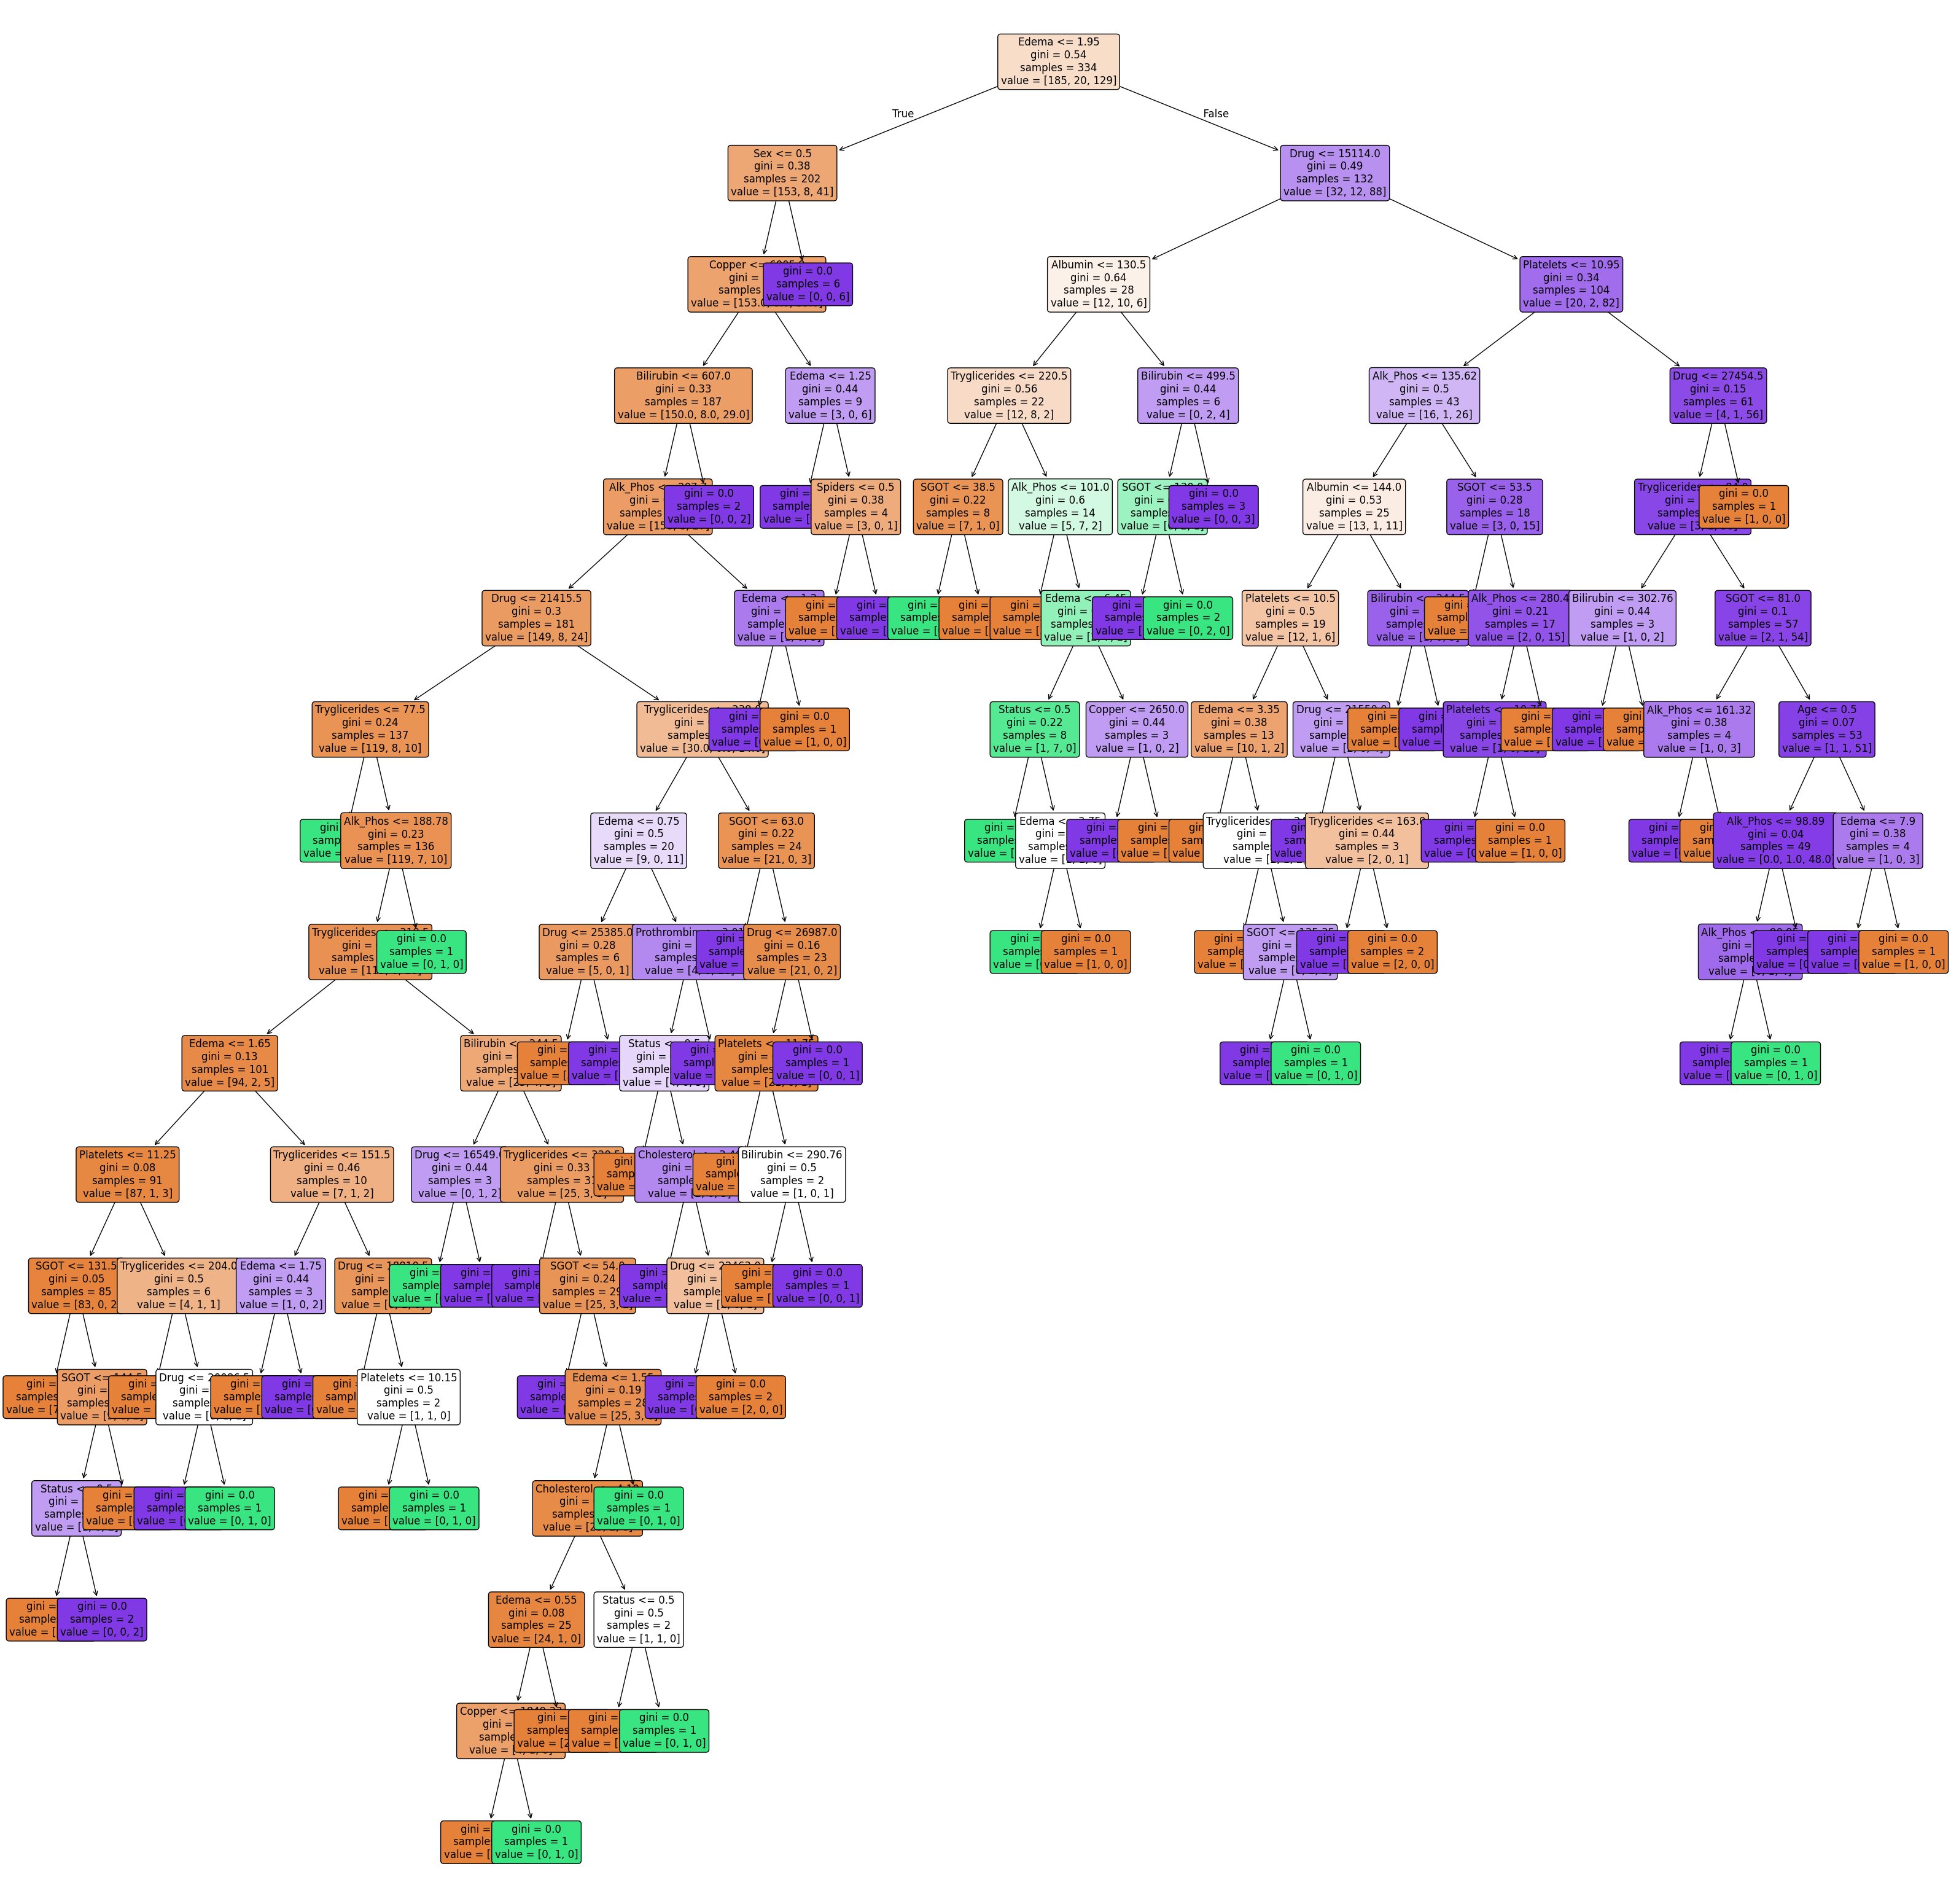

In [39]:
# @title Default title text
plt.figure(figsize = (40,40))
dec_tree = plot_tree(decision_tree=model, feature_names = df.columns, filled = True , fontsize=12, precision = 2,
                     rounded = True)

In [40]:
y_predD = model.predict(X_test)
y_predD

array([0, 0, 0, 0, 0, 0, 0, 2, 2, 0, 0, 0, 0, 1, 2, 2, 1, 2, 0, 0, 2, 1,
       0, 0, 0, 1, 0, 0, 2, 1, 2, 2, 0, 0, 0, 2, 2, 0, 2, 2, 2, 0, 0, 2,
       0, 2, 2, 0, 2, 2, 0, 0, 2, 0, 2, 0, 0, 2, 0, 2, 2, 0, 2, 2, 0, 2,
       0, 2, 2, 2, 0, 2, 0, 0, 2, 2, 2, 2, 2, 0, 1, 2, 2, 0])

In [41]:
print ('accuracy_score: ',accuracy_score(y_test,y_predD))

accuracy_score:  0.6666666666666666


Text(0.5, 1.0, 'Confusion Matrix Model Decision Tree')

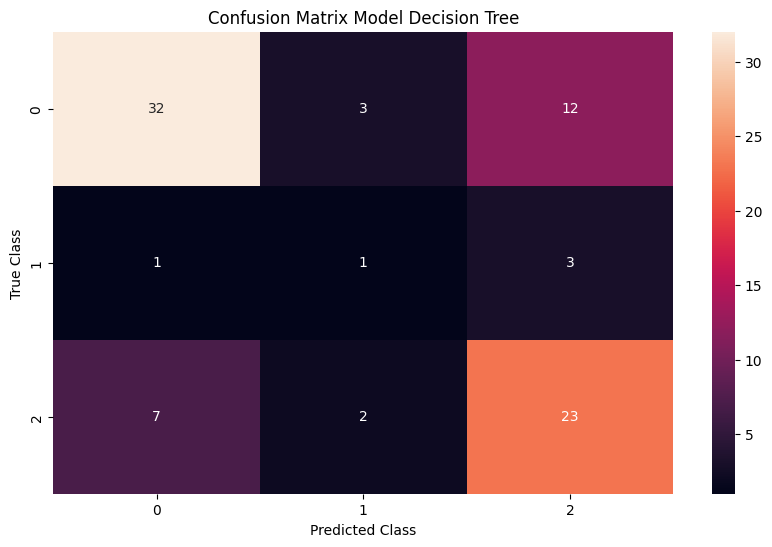

In [42]:

cm = confusion_matrix(y_test, y_predD)
cm

fig = plt.figure(figsize = (10, 6))
sns.heatmap(cm, annot = True, fmt = "d")

# Labeling the X-axis
plt.xlabel("Predicted Class")

# Labeling the Y-axis
plt.ylabel("True Class")

# Give a title to the graph
plt.title("Confusion Matrix Model Decision Tree")

In [43]:

#Model naive bayes
from sklearn.naive_bayes import GaussianNB

#for checking testing results
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score, classification_report, confusion_matrix

In [44]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [45]:
# Distribusi kelas seluruh dataset
print("Distribusi seluruh data:")
print(y.value_counts())

# Distribusi kelas training
print("\nDistribusi data training:")
print(y_train.value_counts())

# Distribusi kelas testing
print("\nDistribusi data testing:")
print(y_test.value_counts())

Distribusi seluruh data:
Status
0    232
2    161
1     25
Name: count, dtype: int64

Distribusi data training:
Status
0    185
2    129
1     20
Name: count, dtype: int64

Distribusi data testing:
Status
0    47
2    32
1     5
Name: count, dtype: int64


In [46]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(
    random_state=42,
    k_neighbors=3
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train, y_train
)

print("Sebelum SMOTE:")
print(y_train.value_counts())

print("\nSesudah SMOTE:")
print(y_train_smote.value_counts())

Sebelum SMOTE:
Status
0    185
2    129
1     20
Name: count, dtype: int64

Sesudah SMOTE:
Status
0    185
2    185
1    185
Name: count, dtype: int64


In [53]:
model = GaussianNB()
model.fit(X_train_smote, y_train_smote)

GaussianNB()

In [54]:
y_pred_smote = model.predict(X_test)
y_pred_smote

array([0, 2, 0, 1, 0, 0, 1, 2, 0, 0, 0, 1, 0, 1, 2, 0, 0, 2, 1, 0, 0, 2,
       0, 1, 0, 2, 0, 0, 0, 0, 2, 1, 2, 1, 0, 0, 2, 0, 0, 0, 0, 0, 2, 1,
       0, 0, 0, 2, 0, 0, 2, 2, 2, 1, 0, 2, 2, 0, 1, 1, 0, 0, 0, 0, 2, 0,
       0, 2, 2, 2, 0, 1, 1, 1, 0, 1, 2, 0, 2, 0, 2, 2, 2, 1])

In [55]:
print ('accuracy_score: ',accuracy_score(y_test,y_pred_smote))

accuracy_score:  0.5595238095238095


Text(0.5, 1.0, 'Confusion Matrix Model Nayve Bayes')

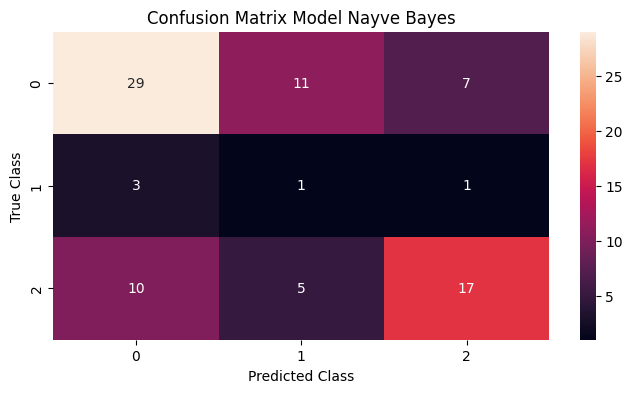

In [52]:
cm1 = confusion_matrix(y_test, y_pred)
cm1


fig = plt.figure(figsize = (8, 4))
sns.heatmap(cm1, annot = True, fmt = "d")

# Labeling the X-axis
plt.xlabel("Predicted Class")

# Labeling the Y-axis
plt.ylabel("True Class")

# Give a title to the graph
plt.title("Confusion Matrix Model Nayve Bayes")